In [1]:
# Install if needed
# !pip -q install tensorflow scikit-learn pandas

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

import pathlib, textwrap, os

print("TensorFlow:", tf.__version__)
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow: 2.19.0


In [2]:
# Upload your CSV in Colab or place locally
df = pd.read_csv("output_with_movement_within_sleep_session.csv")

print(df.head())
print(df.info())

                   timestamp   user_id                       _id  \
0  2026-04-01 21:45:03+00:00  user_001  69cd91e2fd35102c3c5ac1d1   
1  2026-04-01 21:45:04+00:00  user_001  69cd91e4fd35102c3c5ac1d2   
2  2026-04-01 21:45:05+00:00  user_001  69cd91e5fd35102c3c5ac1d3   
3  2026-04-01 21:45:07+00:00  user_001  69cd91e6fd35102c3c5ac1d4   
4  2026-04-01 21:45:08+00:00  user_001  69cd91e8fd35102c3c5ac1d5   

   light_intensity  temperature  humidity  sound_level  distance session_date  \
0             5.00         27.5      55.3           14         0   2026-04-01   
1             5.00         27.5      55.3           28         0   2026-04-01   
2             4.17         26.6      56.0           41         0   2026-04-01   
3             5.00         26.6      56.0           55         0   2026-04-01   
4             4.17         26.6      56.0           68         0   2026-04-01   

  movement  
0      NaN  
1        N  
2        N  
3        N  
4        N  
<class 'pandas.core.frame.

In [3]:
# Fix missing movement labels
df["movement"] = df["movement"].fillna("N")

# Convert labels: N=0, Y=1
df["movement"] = df["movement"].map({"N": 0, "Y": 1})

# Select features
features = ["light_intensity", "temperature", "humidity", "sound_level", "distance"]

# Drop rows with missing values
df = df.dropna(subset=features + ["movement"])

X = df[features].values.astype("float32")
y = df["movement"].values.astype("int32")

print("Shape:", X.shape, y.shape)
print("Class balance:", np.bincount(y))

Shape: (53556, 5) (53556,)
Class balance: [52762   794]


In [4]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# Save scaler parameters (for ESP32 later)
scaler_min = scaler.data_min_
scaler_max = scaler.data_max_

print("Min:", scaler_min)
print("Max:", scaler_max)

Min: [ 0.83 24.   48.9   6.    0.  ]
Max: [166.67  31.9   86.5  405.   373.  ]


In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "Val:", X_val.shape)

Train: (42844, 5) Val: (10712, 5)


In [6]:
model = keras.Sequential([
    layers.Input(shape=(5,)),   # 5 sensor inputs
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 250 (1000.00 B)

 Trainable params: 250 (1000.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=16,
    verbose=1
)

Epoch 1/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9854 - loss: 0.0607 - val_accuracy: 0.9843 - val_loss: 0.0561
Epoch 2/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9854 - loss: 0.0551 - val_accuracy: 0.9843 - val_loss: 0.0539
Epoch 3/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9854 - loss: 0.0537 - val_accuracy: 0.9843 - val_loss: 0.0529
Epoch 4/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9854 - loss: 0.0526 - val_accuracy: 0.9843 - val_loss: 0.0540
Epoch 5/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9854 - loss: 0.0522 - val_accuracy: 0.9843 - val_loss: 0.0530
Epoch 6/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9854 - loss: 0.0516 - val_accuracy: 0.9843 - val_loss: 0.0528
Epoch 7/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9853 - loss: 0.0513 - val_accuracy: 0.9843 - val_loss: 0.0527
Epoch 8/20
2678/2678 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9854 - loss: 0.0514 - 

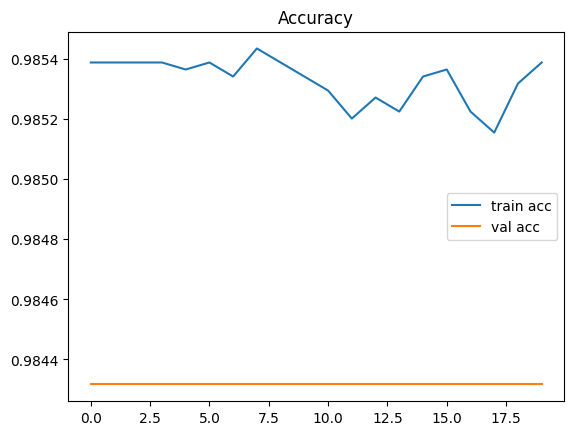

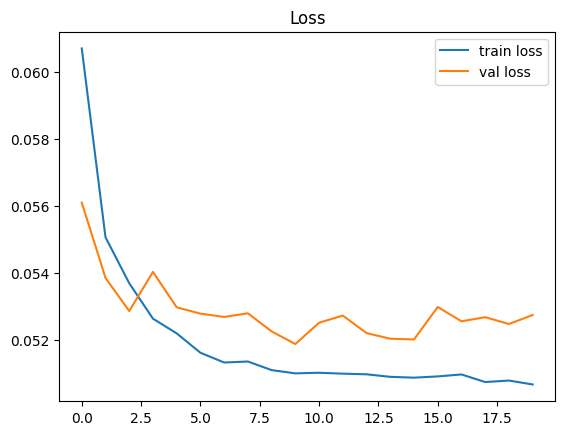

In [8]:
plt.figure()
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.legend()
plt.title("Accuracy")
plt.show()

plt.figure()
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend()
plt.title("Loss")
plt.show()

In [9]:
val_loss, val_acc = model.evaluate(X_val, y_val)
print(f"Validation Accuracy: {val_acc:.3f}")

335/335 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9843 - loss: 0.0528
Validation Accuracy: 0.984


In [10]:
sample = X_val[:5]
preds = model.predict(sample)

for i, p in enumerate(preds):
    pred_class = np.argmax(p)
    print(f"Sample {i}: {p} → Pred={pred_class} ({'MOVE' if pred_class==1 else 'NO MOVE'})")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Sample 0: [0.99879396 0.00120601] → Pred=0 (NO MOVE)
Sample 1: [0.99150264 0.00849738] → Pred=0 (NO MOVE)
Sample 2: [0.9978757  0.00212434] → Pred=0 (NO MOVE)
Sample 3: [9.9984157e-01 1.5844137e-04] → Pred=0 (NO MOVE)
Sample 4: [0.95323616 0.04676386] → Pred=0 (NO MOVE)


In [12]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

out_dir = pathlib.Path("export")
out_dir.mkdir(exist_ok=True)

tflite_path = out_dir / "model.tflite"
tflite_path.write_bytes(tflite_model)

print("Saved:", tflite_path, "Size:", tflite_path.stat().st_size)

In [ ]:
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model_q = converter_q.convert()

tflite_q_path = out_dir / "model_quant.tflite"
tflite_q_path.write_bytes(tflite_model_q)

print("Saved:", tflite_q_path, "Size:", tflite_q_path.stat().st_size)

In [ ]:
def run_tflite(tflite_bytes, inputs):
    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    outputs = []
    for x in inputs:
        interpreter.set_tensor(input_details[0]["index"], x.reshape(1,5))
        interpreter.invoke()
        out = interpreter.get_tensor(output_details[0]["index"])
        outputs.append(out[0])

    return np.array(outputs)

test = X_val[:5]

print("TFLite output:")
print(run_tflite(tflite_model, test))

In [ ]:
def tflite_to_c_array(tflite_bytes, var_name):
    hex_array = ", ".join([f"0x{b:02x}" for b in tflite_bytes])
    return f"""
#ifndef {var_name.upper()}_H
#define {var_name.upper()}_H

const unsigned char {var_name}[] = {{
{hex_array}
}};

const unsigned int {var_name}_len = sizeof({var_name});

#endif
"""

header = tflite_to_c_array(tflite_model, "model_tflite")

with open("export/model.h", "w") as f:
    f.write(header)

print("model.h generated!")

In [ ]:
from google.colab import files

files.download("export/model.tflite")
files.download("export/model_quant.tflite")
files.download("export/model.h")